In [ ]:
# Repo bootstrap: notebooks use paths relative to the repo root and import from src/
import os, sys
from pathlib import Path

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "src" / "pipeline.py").exists())
os.chdir(ROOT)
sys.path.insert(0, str(ROOT / "src"))

In [1]:
import os
import numpy as np
import pandas as pd
import cv2
from pathlib import Path
import torch
from torch.utils.data import Dataset, DataLoader
from torchvision import datasets, transforms
from PIL import Image
import matplotlib.pyplot as plt
from tqdm import tqdm
import random
import shutil



In [2]:
# reproducibility
SEED = 42
np.random.seed(SEED)
random.seed(SEED)
torch.manual_seed(SEED)


In [3]:
# Config
PATCH_SIZE = 224
NEG_RATIO = 2/3 # for 60-40 global ratio
STRIDE = PATCH_SIZE // 40

IMAGES_DIR = "data/TreeBoxes_v0.11/images"
CSV_PATH = "data/TreeBoxes_v0.11/random.csv"


In [4]:
## helper functions

def compute_iou(box1,box2):
    """box1 and box2 = [x1,y1,x2,y2]"""
    x1 = max(box1[0],box2[0])
    y1 = max(box1[1],box2[1])
    x2 = min(box1[2], box2[2])
    y2 = min(box1[3], box2[3])
    
    inter_w = max(0,x2-x1)
    inter_h = max(0,y2-y1)
    inter_area = inter_w*inter_h

    area1 = (box1[2]-box1[0]) * (box1[3]-box1[1])
    area2 = (box2[2]-box2[0]) * (box2[3]-box2[1])

    iou = inter_area / (area1+area2-inter_area) if area1+area2-inter_area > 0 else 0
    return iou

def max_iou_trees(cx,cy,side,img_boxes):
    px1 = cx-side/2
    px2 = cx+side/2
    py1 = cy-side/2
    py2 = cy+side/2
    
    max_iou = 0
    for box in img_boxes:
        iou = compute_iou([px1,py1,px2,py2],box)
        max_iou = max(max_iou,iou)
    return max_iou

def extract_positive_patch_Wpadding(img,xmin,ymin,xmax,ymax,ratio_padding):
    """Extract one single patch, adding a padding of ratio_padding = 1.2 ofr 20%, and resizing to PATCH_SIZE"""
    him, wim = img.shape[:2]
        
    # box center
    cx,cy = (xmin+xmax) / 2, (ymin+ymax) / 2
    w_box = xmax-xmin
    h_box = ymax-ymin

    # padding
    w_exp = w_box*ratio_padding
    h_exp = h_box*ratio_padding
    
    #square
    side = max(w_exp,h_exp)
    x1 = cx - side/2
    y1 = cy - side/2
    x2 = cx + side/2
    y2 = cy + side/2

    #clamp if image out of bounds
    x1 =  max(0,x1)
    y1 = max(0,y1)
    x2 = min(wim,x2)
    y2 = min(him,y2)

    #round
    x1,x2 = int(round(x1)),int(round(x2))
    y1,y2 = int(round(y1)),int(round(y2))
    
    patch = img[y1:y2,x1:x2] 
    patch = cv2.resize(patch,(PATCH_SIZE,PATCH_SIZE))
    return patch,side

def extract_negative_patch(img,cx,cy,side):
    h,w = img.shape[:2]
    x1 = cx - side/2
    y1 = cy - side/2
    x2 = cx + side/2
    y2 = cy + side/2

    #clamp if image out of bounds
    x1 =  max(0,x1)
    y1 = max(0,y1)
    x2 = min(w,x2)
    y2 = min(h,y2)

    #round
    x1,x2 = int(round(x1)),int(round(x2))
    y1,y2 = int(round(y1)),int(round(y2))

    patch = img[y1:y2,x1:x2]
    patch = cv2.resize(patch,(PATCH_SIZE,PATCH_SIZE))
    return patch 

def save_patch(patch, filepath):
    """save normalized patch as png"""
    cv2.imwrite(str(filepath),cv2.cvtColor(patch, cv2.COLOR_RGB2BGR))



In [6]:
def extract_patches_to_disk(images_dir,output_base,ratio_padding,version,iou_neg_thresh):        
    df = pd.read_csv(CSV_PATH)
    pos_median_sides = []
    output_dir = Path(output_base) / f"patches_v{version}_seed{SEED}_pad{ratio_padding}_iouth{iou_neg_thresh}"
    pos_dir = output_dir / "positive"
    neg_dir = output_dir / "negative"

    if os.path.exists(pos_dir):
        shutil.rmtree(pos_dir)
    os.makedirs(pos_dir)

    if os.path.exists(neg_dir):
        shutil.rmtree(neg_dir)
    os.makedirs(neg_dir)
    
    metadata = []
    total_pos_count = 0
    total_neg_count = 0
    
    #print("extracting pos patches")
    for fname in tqdm(df['filename'].unique()):
        pos_sides = []
        neg_count = 0,0

        img_path = Path(images_dir) / fname
        img = cv2.imread(str(img_path))
        img = cv2.cvtColor(img,cv2.COLOR_BGR2RGB)
        h,w,_ = img.shape

        img_boxes = df[df['filename'] == fname][['xmin','ymin','xmax','ymax']].astype(int).values

        #positive with a tree in the image around the center
        for _,row in df[df['filename'] == fname].iterrows():

            xmin,ymin,xmax,ymax = row[['xmin','ymin','xmax','ymax']].astype(int)
            cx,cy = (xmin+xmax) // 2, (ymin+ymax) // 2
            patch,side = extract_positive_patch_Wpadding(img,xmin,ymin,xmax,ymax,ratio_padding)
            pos_sides.append(side)
            patch_path = pos_dir / f"{total_pos_count}.png"
            save_patch(patch,patch_path)
            
            metadata.append({
                'patch_id':total_pos_count,
                'filename':fname,
                'cx':cx,'cy':cy,
                'label':1,
                'type':'positive'
                })
            total_pos_count+= 1
           
        median_side = np.median(pos_sides)
        print(f"median pos side for {fname}: {median_side}")
        pos_median_sides.append(median_side)

        #negatives
        n_neg_target = int(len(img_boxes) * NEG_RATIO)
        used_cells = set() # for duplicates
        stride = median_side/10
        
        neg_count = 0
        attempts = 0
        max_attempts = 10000

        while neg_count < n_neg_target and attempts < max_attempts:
            cx = np.random.randint(int(median_side/2), w - int(median_side/2)) #from left to right
            cy = np.random.randint(int(median_side/2), h - int(median_side/2)) #from bottom to top
            # deduplicate
            gx,gy = cx // stride, cy // stride
            if (gx,gy) in used_cells:
                print("alr used")
                attempts += 1
                continue
            
            max_iou = max_iou_trees(cx,cy,median_side,img_boxes)
            if max_iou < iou_neg_thresh:        
                patch = extract_negative_patch(img,cx,cy,median_side)
                patch_path = neg_dir / f'{total_neg_count}.png'
                save_patch(patch,patch_path)

                metadata.append({
                    'patch_id':total_neg_count,
                    'filename':fname,
                    'cx':cx,'cy':cy,
                    'label':0,
                    'type':'negative'
                })
                used_cells.add((gx,gy))
                neg_count += 1
                total_neg_count+= 1
            attempts += 1
            
        if attempts >= max_attempts:
            print(f"too many attempts for {fname}")
    
    metadata_df = pd.DataFrame(metadata)
    metadata_path = output_dir / "metadata.csv"
    metadata_df.to_csv(metadata_path,index=False)
    print(f"{total_pos_count} positive and {total_neg_count} negative pacthes")
    print("median sides = ",pos_median_sides)
    return metadata_df,pos_median_sides



In [7]:
output_base = "patches_dataset"
RATIO_PAD = 1.6 # 40%
iou_neg_thresh = 0.09
version = 3
metadata,pos_median_sides = extract_patches_to_disk(IMAGES_DIR,output_base,RATIO_PAD,version,iou_neg_thresh)


  0%|          | 0/32 [00:00<?, ?it/s]

median pos side for 5030-10-4.png: 38.400000000000006
alr used
alr used


  3%|▎         | 1/32 [00:04<02:25,  4.70s/it]

median pos side for 5032-6-6.png: 60.800000000000004
alr used
alr used
alr used
alr used
alr used
alr used
alr used
alr used
alr used
alr used
alr used
alr used
alr used
alr used
alr used
alr used
alr used
alr used
alr used
alr used
alr used
alr used
alr used
alr used
alr used
alr used
alr used
alr used
alr used
alr used
alr used
alr used
alr used
alr used
alr used
alr used
alr used
alr used
alr used
alr used
alr used
alr used
alr used
alr used
alr used
alr used
alr used
alr used
alr used
alr used
alr used
alr used
alr used
alr used
alr used
alr used
alr used
alr used
alr used
alr used
alr used
alr used
alr used
alr used
alr used
alr used
alr used


  6%|▋         | 2/32 [00:24<06:47, 13.57s/it]

alr used
alr used
median pos side for 5032-7-10.png: 59.2
alr used
alr used
alr used
alr used
alr used
alr used
alr used
alr used
alr used
alr used
alr used
alr used
alr used
alr used
alr used
alr used
alr used
alr used
alr used
alr used
alr used
alr used
alr used
alr used
alr used
alr used
alr used
alr used
alr used
alr used
alr used
alr used
alr used
alr used
alr used
alr used
alr used
alr used
alr used
alr used
alr used
alr used
alr used
alr used
alr used
alr used
alr used
alr used
alr used
alr used
alr used
alr used
alr used
alr used
alr used


... (56 outputs left out)

 97%|█████████▋| 31/32 [04:27<00:15, 15.69s/it]

too many attempts for B06_0143.JPG
median pos side for Pfinztal_6.png: 11.200000000000001
alr used
alr used
alr used


100%|██████████| 32/32 [04:34<00:00,  8.59s/it]

13577 positive and 6246 negative pacthes
median sides =  [np.float64(38.400000000000006), np.float64(60.800000000000004), np.float64(59.2), np.float64(27.200000000000003), np.float64(32.0), np.float64(27.200000000000003), np.float64(11.200000000000001), np.float64(11.200000000000001), np.float64(60.0), np.float64(73.60000000000001), np.float64(116.80000000000001), np.float64(27.200000000000003), np.float64(65.60000000000001), np.float64(113.60000000000001), np.float64(126.4), np.float64(113.60000000000001), np.float64(88.0), np.float64(104.0), np.float64(174.4), np.float64(179.20000000000002), np.float64(62.400000000000006), np.float64(62.400000000000006), np.float64(63.2), np.float64(83.2), np.float64(36.800000000000004), np.float64(41.6), np.float64(582.4), np.float64(225.60000000000002), np.float64(190.4), np.float64(385.6), np.float64(185.60000000000002), np.float64(11.200000000000001)]


In [8]:
pos_median_sides

[np.float64(38.400000000000006),
 np.float64(60.800000000000004),
 np.float64(59.2),
 np.float64(27.200000000000003),
 np.float64(32.0),
 np.float64(27.200000000000003),
 np.float64(11.200000000000001),
 np.float64(11.200000000000001),
 np.float64(60.0),
 np.float64(73.60000000000001),
 np.float64(116.80000000000001),
 np.float64(27.200000000000003),
 np.float64(65.60000000000001),
 np.float64(113.60000000000001),
 np.float64(126.4),
 np.float64(113.60000000000001),
 np.float64(88.0),
 np.float64(104.0),
 np.float64(174.4),
 np.float64(179.20000000000002),
 np.float64(62.400000000000006),
 np.float64(62.400000000000006),
 np.float64(63.2),
 np.float64(83.2),
 np.float64(36.800000000000004),
 np.float64(41.6),
 np.float64(582.4),
 np.float64(225.60000000000002),
 np.float64(190.4),
 np.float64(385.6),
 np.float64(185.60000000000002),
 np.float64(11.200000000000001)]

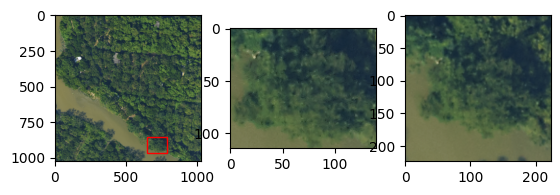

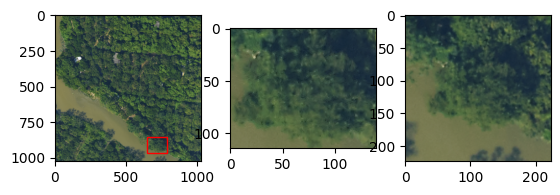

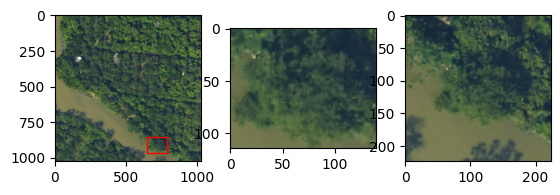

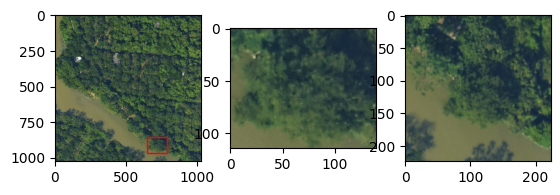

In [ ]:
######## testing pos

df = pd.read_csv(CSV_PATH)
row = df.iloc[1000]
img_path = Path(IMAGES_DIR) / row["filename"]
img = cv2.imread(str(img_path))
img_rgb = cv2.cvtColor(img,cv2.COLOR_BGR2RGB)
h,w,nchan = img_rgb.shape #1024*1024*3
xmin,ymin,xmax,ymax = row[['xmin','ymin','xmax','ymax']].astype(int)

patch = img_rgb[ymin:ymax,xmin:xmax]
for RATIO_PAD in [1.2,1.4,1.6,2.0]:
    npatch,_ = extract_positive_patch_Wpadding(img_rgb,xmin,ymin,xmax,ymax,RATIO_PAD)

    fig,axes = plt.subplots(1,3)
    axes[0].imshow(img_rgb)
    rect = plt.Rectangle((xmin,ymin),xmax-xmin,ymax-ymin,facecolor="none",edgecolor="red")
    axes[0].add_patch(rect)

    axes[1].imshow(patch)
    axes[2].imshow(npatch)

    output = Path("eda_bbox")
    if not os.path.exists(output):
        os.makedirs(output)
    plt.savefig(output / f"pos_patch_example{RATIO_PAD}.png")
#cv2.imwrite(str(output / "postest.png"),cv2.cvtColor(patch, cv2.COLOR_RGB2BGR))


[ WARN:0@514.434] global grfmt_tiff.cpp:122 TIFF_Warning TIFFReadDirectory: Unknown field with tag 33550 (0x830e) encountered
[ WARN:0@514.434] global grfmt_tiff.cpp:122 TIFF_Warning TIFFReadDirectory: Unknown field with tag 33922 (0x8482) encountered
[ WARN:0@514.434] global grfmt_tiff.cpp:122 TIFF_Warning TIFFReadDirectory: Unknown field with tag 34735 (0x87af) encountered
[ WARN:0@514.434] global grfmt_tiff.cpp:122 TIFF_Warning TIFFReadDirectory: Unknown field with tag 34737 (0x87b1) encountered
[ WARN:0@514.434] global grfmt_tiff.cpp:122 TIFF_Warning TIFFReadDirectory: Unknown field with tag 42112 (0xa480) encountered
[ WARN:0@514.434] global grfmt_tiff.cpp:122 TIFF_Warning TIFFReadDirectory: Unknown field with tag 42113 (0xa481) encountered


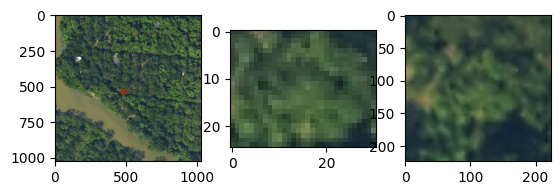

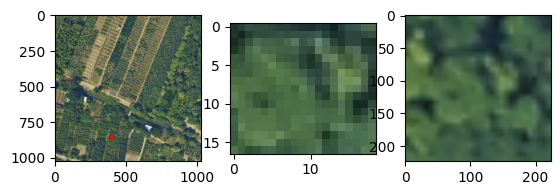

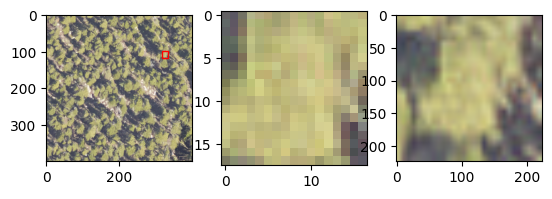

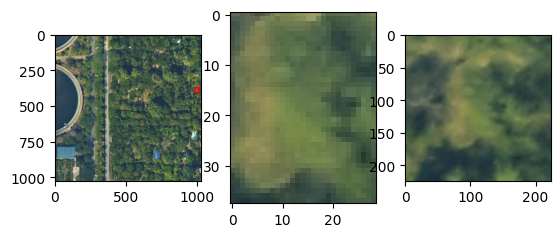

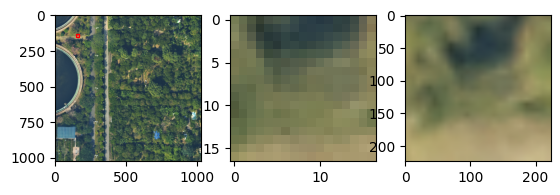

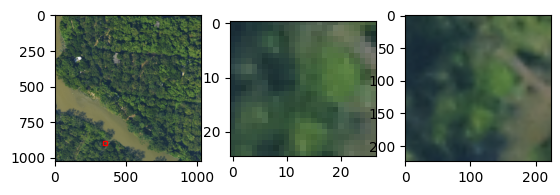

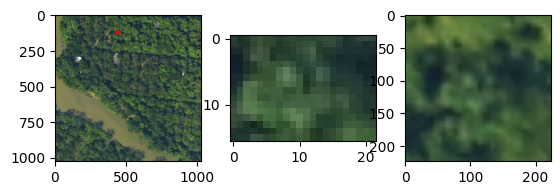

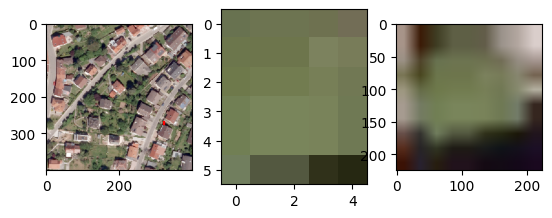

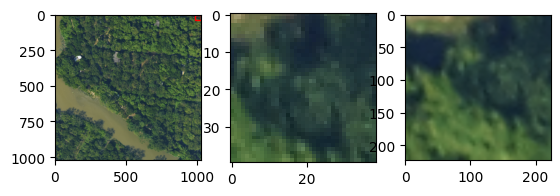

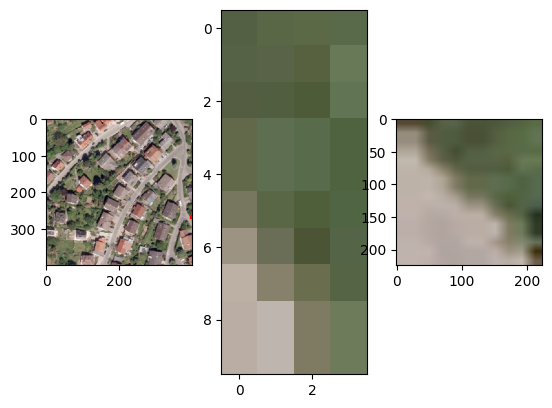

In [9]:
######## testing pos
df = pd.read_csv(CSV_PATH)
RATIO_PAD = 1.6

for _ in range(10):
    i = random.randint(0,5000)
    row = df.iloc[i]
    img_path = Path(IMAGES_DIR) / row["filename"]
    img = cv2.imread(str(img_path))
    img_rgb = cv2.cvtColor(img,cv2.COLOR_BGR2RGB)
    h,w,nchan = img_rgb.shape
    xmin,ymin,xmax,ymax = row[['xmin','ymin','xmax','ymax']].astype(int)
    patch = img_rgb[ymin:ymax,xmin:xmax]
    npatch,_ = extract_positive_patch_Wpadding(img_rgb,xmin,ymin,xmax,ymax,RATIO_PAD)

    fig,axes = plt.subplots(1,3)
    axes[0].imshow(img_rgb)
    rect = plt.Rectangle((xmin,ymin),xmax-xmin,ymax-ymin,facecolor="none",edgecolor="red")
    axes[0].add_patch(rect)

    axes[1].imshow(patch)
    axes[2].imshow(npatch)


#output = Path("test_patch")
#if os.path.exists(output):
#    shutil.rmtree(output)
#os.makedirs(output)
#cv2.imwrite(str(output / "test.png"),cv2.cvtColor(patch, cv2.COLOR_RGB2BGR))


5030-10-4.png
0


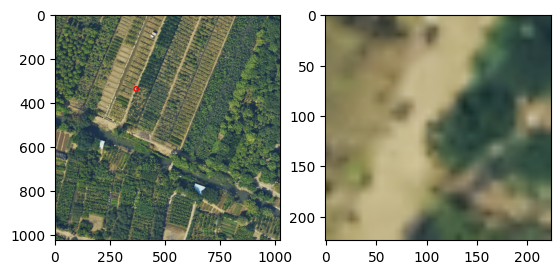

0


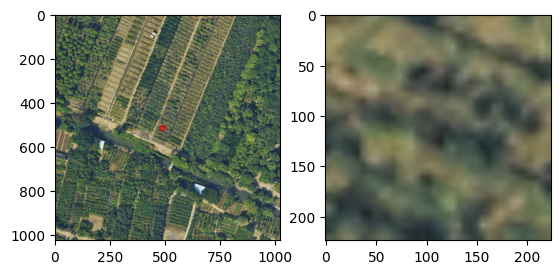

5032-6-6.png
0.0028078242668246665


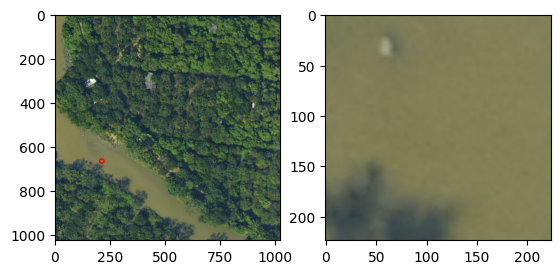

0


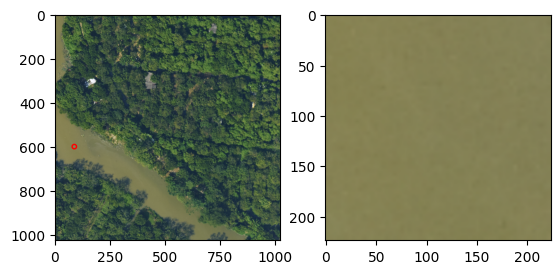

5032-7-10.png
0


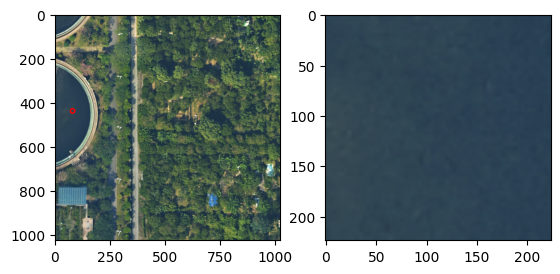

0.08393702244665943


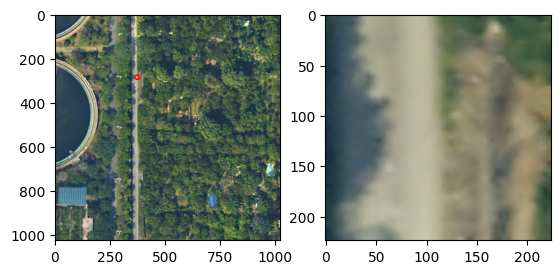

NIWO_002_2018.tif
0.015398911456259061


[ WARN:0@601.922] global grfmt_tiff.cpp:122 TIFF_Warning TIFFReadDirectory: Unknown field with tag 33550 (0x830e) encountered
[ WARN:0@601.922] global grfmt_tiff.cpp:122 TIFF_Warning TIFFReadDirectory: Unknown field with tag 33922 (0x8482) encountered
[ WARN:0@601.922] global grfmt_tiff.cpp:122 TIFF_Warning TIFFReadDirectory: Unknown field with tag 34735 (0x87af) encountered
[ WARN:0@601.922] global grfmt_tiff.cpp:122 TIFF_Warning TIFFReadDirectory: Unknown field with tag 34737 (0x87b1) encountered
[ WARN:0@601.922] global grfmt_tiff.cpp:122 TIFF_Warning TIFFReadDirectory: Unknown field with tag 42112 (0xa480) encountered
[ WARN:0@601.922] global grfmt_tiff.cpp:122 TIFF_Warning TIFFReadDirectory: Unknown field with tag 42113 (0xa481) encountered


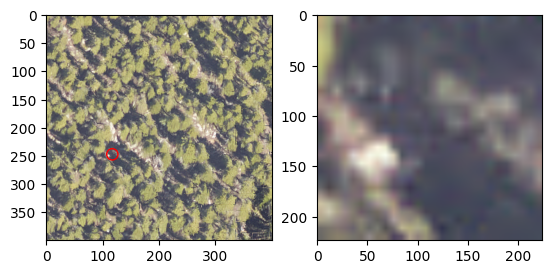

0.03572207441008413


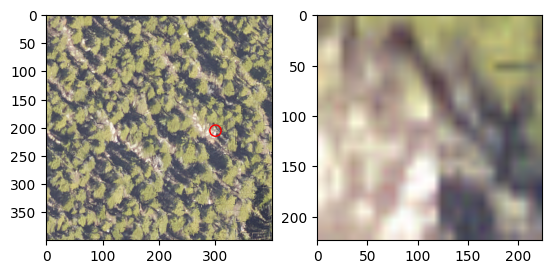

NIWO_001_2018.tif
0.03436426116838488


[ WARN:0@602.393] global grfmt_tiff.cpp:122 TIFF_Warning TIFFReadDirectory: Unknown field with tag 33550 (0x830e) encountered
[ WARN:0@602.393] global grfmt_tiff.cpp:122 TIFF_Warning TIFFReadDirectory: Unknown field with tag 33922 (0x8482) encountered
[ WARN:0@602.393] global grfmt_tiff.cpp:122 TIFF_Warning TIFFReadDirectory: Unknown field with tag 34735 (0x87af) encountered
[ WARN:0@602.393] global grfmt_tiff.cpp:122 TIFF_Warning TIFFReadDirectory: Unknown field with tag 34737 (0x87b1) encountered
[ WARN:0@602.393] global grfmt_tiff.cpp:122 TIFF_Warning TIFFReadDirectory: Unknown field with tag 42112 (0xa480) encountered
[ WARN:0@602.393] global grfmt_tiff.cpp:122 TIFF_Warning TIFFReadDirectory: Unknown field with tag 42113 (0xa481) encountered


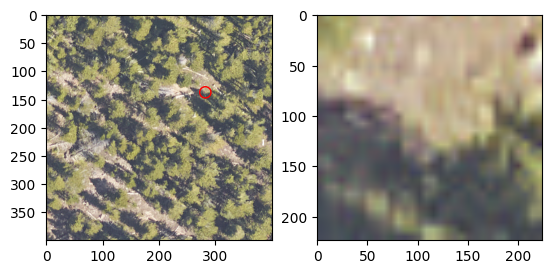

0.04946043165467626


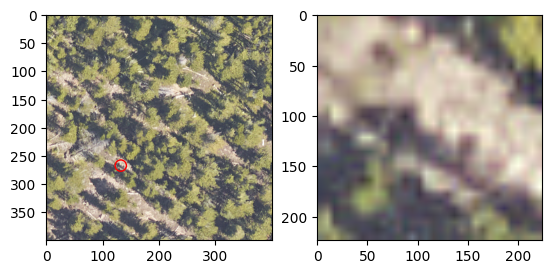

NIWO_014_2018.tif
0.07731732318055357


[ WARN:0@602.811] global grfmt_tiff.cpp:122 TIFF_Warning TIFFReadDirectory: Unknown field with tag 33550 (0x830e) encountered
[ WARN:0@602.811] global grfmt_tiff.cpp:122 TIFF_Warning TIFFReadDirectory: Unknown field with tag 33922 (0x8482) encountered
[ WARN:0@602.811] global grfmt_tiff.cpp:122 TIFF_Warning TIFFReadDirectory: Unknown field with tag 34735 (0x87af) encountered
[ WARN:0@602.811] global grfmt_tiff.cpp:122 TIFF_Warning TIFFReadDirectory: Unknown field with tag 34737 (0x87b1) encountered
[ WARN:0@602.811] global grfmt_tiff.cpp:122 TIFF_Warning TIFFReadDirectory: Unknown field with tag 42112 (0xa480) encountered
[ WARN:0@602.811] global grfmt_tiff.cpp:122 TIFF_Warning TIFFReadDirectory: Unknown field with tag 42113 (0xa481) encountered


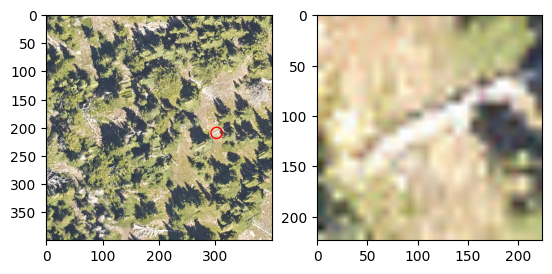

0.06143520908621576


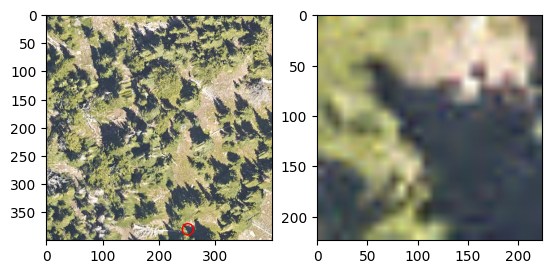

Pfinztal_7.png
0


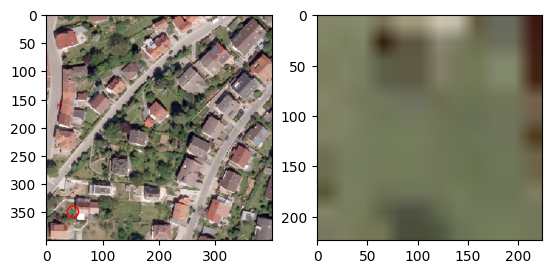

0


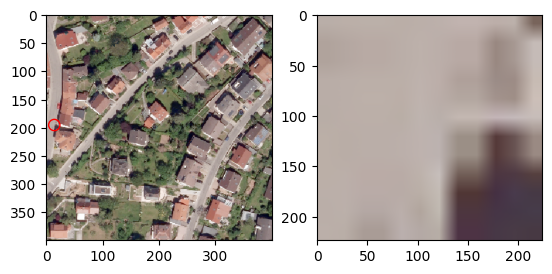

Pfinztal_10.png
0


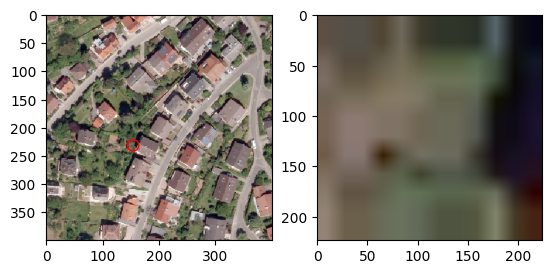

0


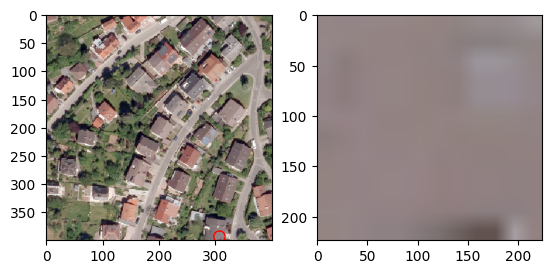

tile_45_72_lat_50.88377_lon_4.68583.png
0.045471914405808174


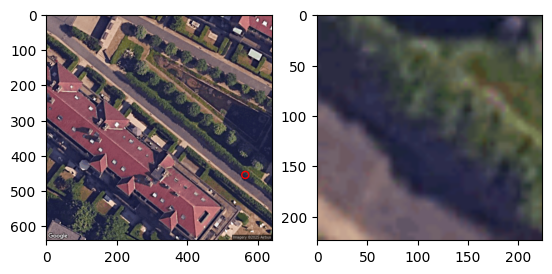

0


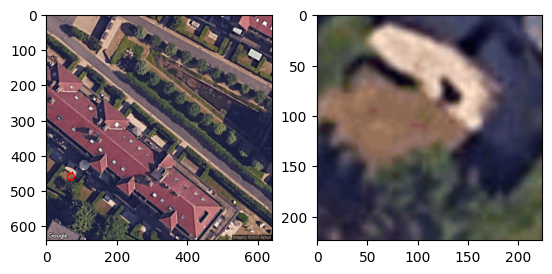

tile_58_87_lat_50.89147_lon_4.69642.png
0.007728170019740484


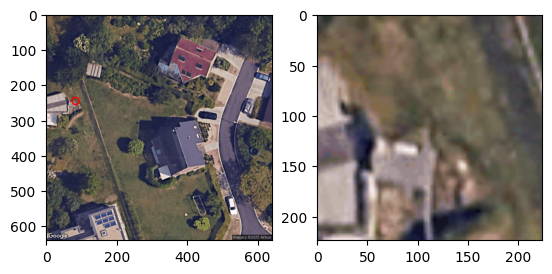

0


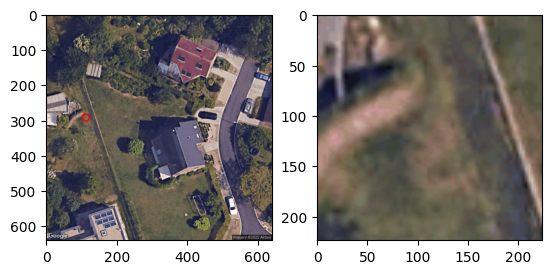

tile_75_37_lat_50.86578_lon_4.71026.png
0.05763346916979257


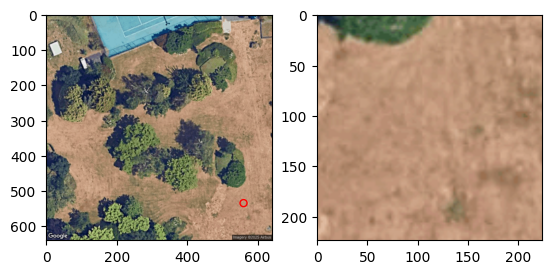

0


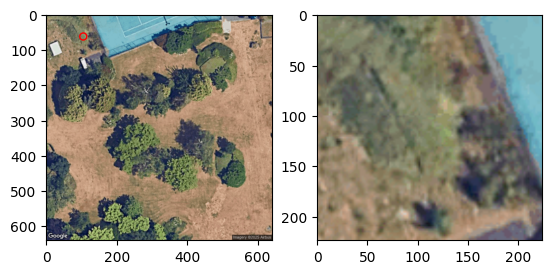

train_5012.png
0


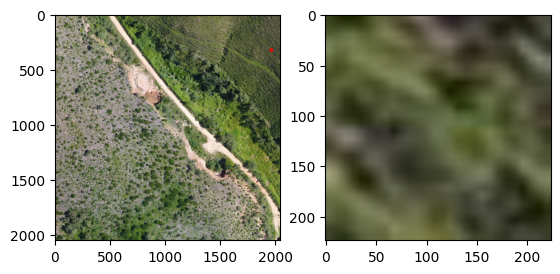

0


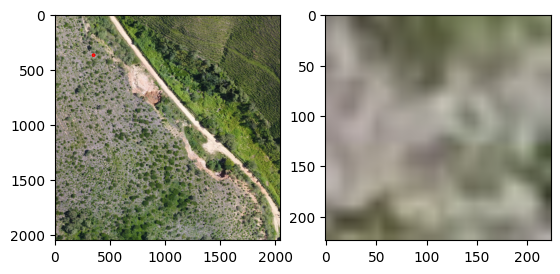

train_824.png
0


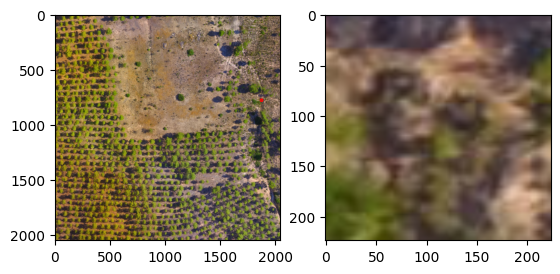

0


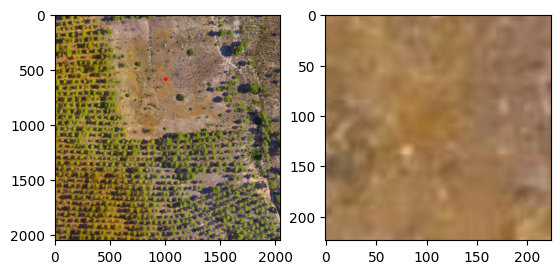

20231208_asforestnorthe2_m3m_rgb_tile_valid_1777_gr0p045_7104_1776.png
0.08855556041457109


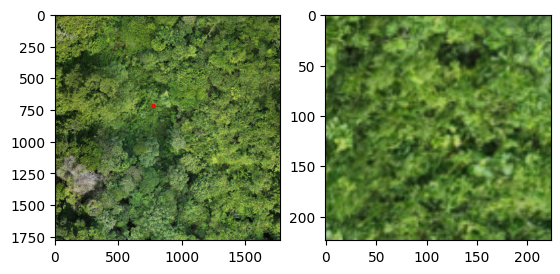

0.058740001511457085


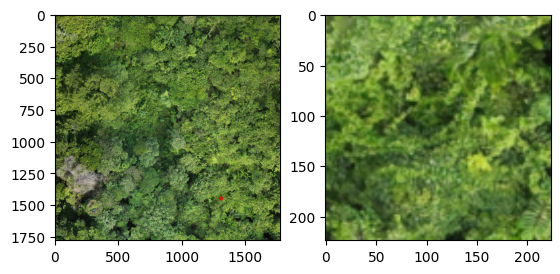

20231208_asforestnorthe2_m3m_rgb_tile_valid_1777_gr0p045_7992_1776.png
0.08794074254802481


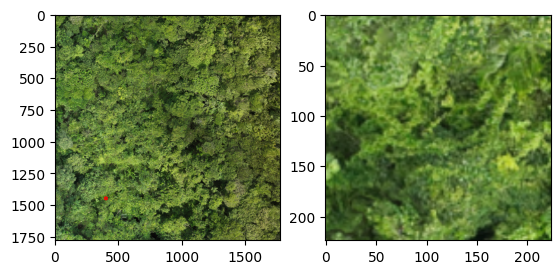

0.08582531479422856


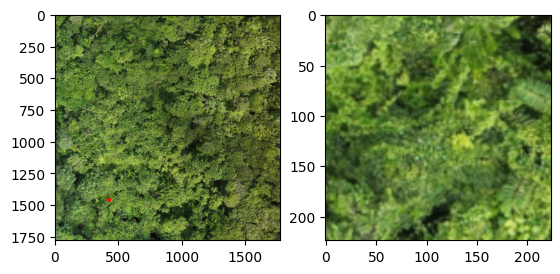

2019_BLAN_3_754000_4334000_image_tile_15.jpg
too many attempts for 2019_BLAN_3_754000_4334000_image_tile_15.jpg
2019_BLAN_3_762000_4326000_image_tile_55.jpg
0.08004941321803583


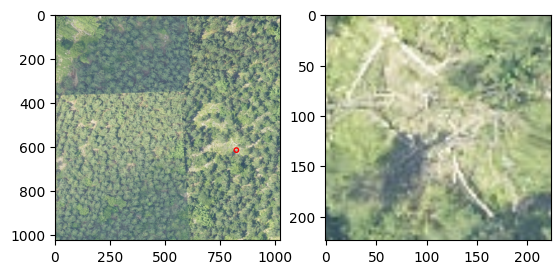

0.08502404128063798


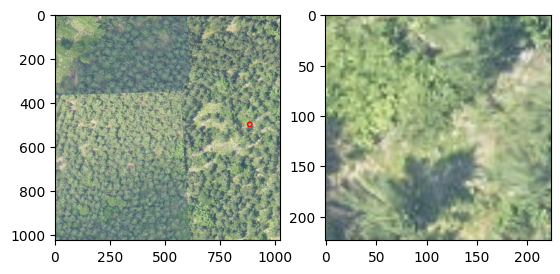

2019_BLAN_3_762000_4326000_image_tile_62.jpg
0.08598372781065089


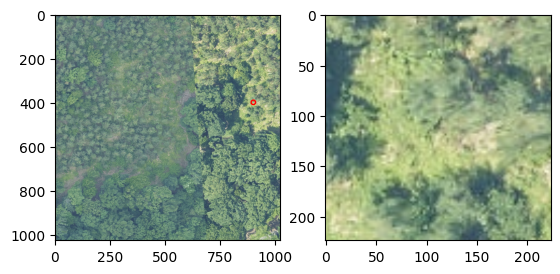

alr used
0.08598372781065089


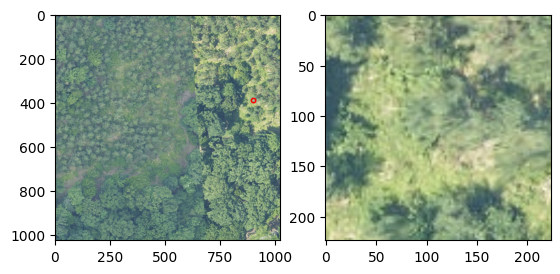

000089_ortho_169.png
0.03656154060842869


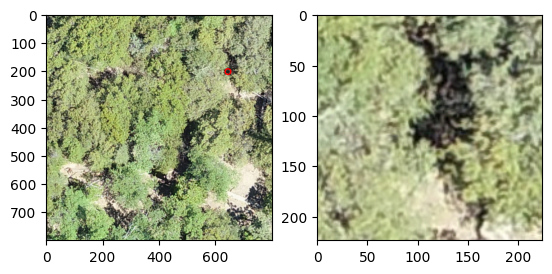

0.0004937116474727399


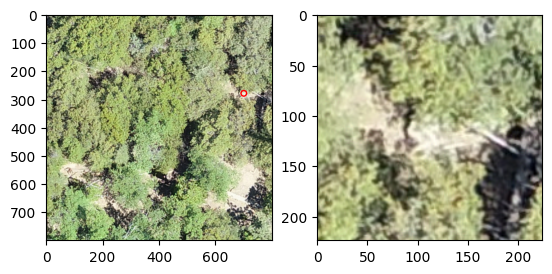

000089_ortho_386.png
0.08571777829268698


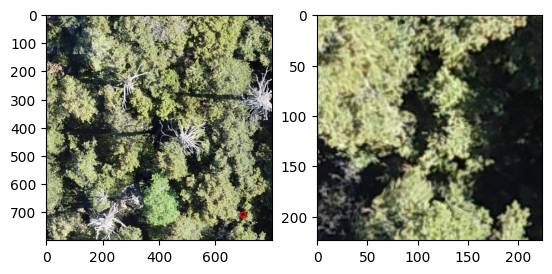

0.0782774314786373


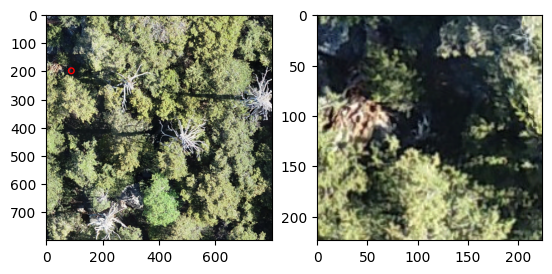

HARV_047_2018.tif
0.0006141945841415824


[ WARN:0@633.696] global grfmt_tiff.cpp:122 TIFF_Warning TIFFReadDirectory: Unknown field with tag 33550 (0x830e) encountered
[ WARN:0@633.696] global grfmt_tiff.cpp:122 TIFF_Warning TIFFReadDirectory: Unknown field with tag 33922 (0x8482) encountered
[ WARN:0@633.696] global grfmt_tiff.cpp:122 TIFF_Warning TIFFReadDirectory: Unknown field with tag 34735 (0x87af) encountered
[ WARN:0@633.696] global grfmt_tiff.cpp:122 TIFF_Warning TIFFReadDirectory: Unknown field with tag 34737 (0x87b1) encountered
[ WARN:0@633.696] global grfmt_tiff.cpp:122 TIFF_Warning TIFFReadDirectory: Unknown field with tag 42112 (0xa480) encountered
[ WARN:0@633.696] global grfmt_tiff.cpp:122 TIFF_Warning TIFFReadDirectory: Unknown field with tag 42113 (0xa481) encountered


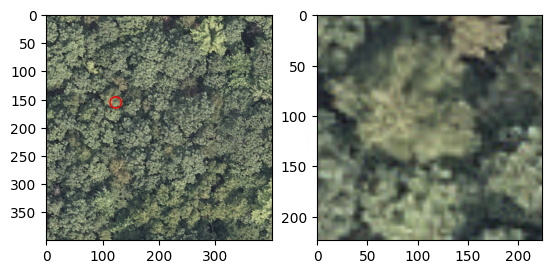

0.05537303625828795


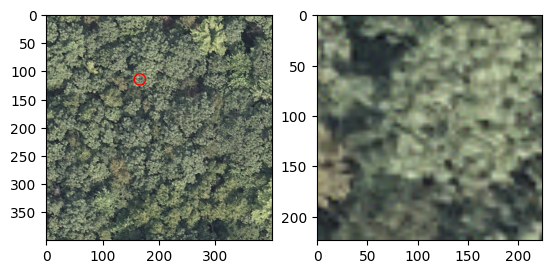

HARV_047_2019.tif
0


[ WARN:0@634.362] global grfmt_tiff.cpp:122 TIFF_Warning TIFFReadDirectory: Unknown field with tag 33550 (0x830e) encountered
[ WARN:0@634.362] global grfmt_tiff.cpp:122 TIFF_Warning TIFFReadDirectory: Unknown field with tag 33922 (0x8482) encountered
[ WARN:0@634.362] global grfmt_tiff.cpp:122 TIFF_Warning TIFFReadDirectory: Unknown field with tag 34735 (0x87af) encountered
[ WARN:0@634.362] global grfmt_tiff.cpp:122 TIFF_Warning TIFFReadDirectory: Unknown field with tag 34737 (0x87b1) encountered
[ WARN:0@634.362] global grfmt_tiff.cpp:122 TIFF_Warning TIFFReadDirectory: Unknown field with tag 42112 (0xa480) encountered
[ WARN:0@634.362] global grfmt_tiff.cpp:122 TIFF_Warning TIFFReadDirectory: Unknown field with tag 42113 (0xa481) encountered


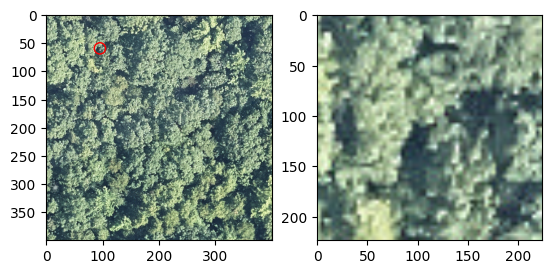

0


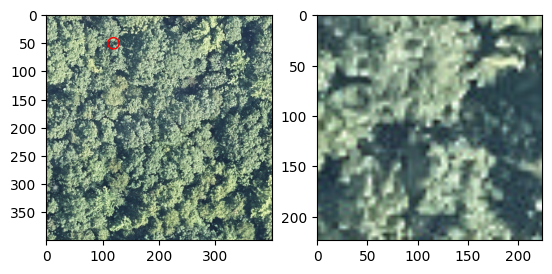

HARV_047_2022.tif
0


[ WARN:0@634.801] global grfmt_tiff.cpp:122 TIFF_Warning TIFFReadDirectory: Unknown field with tag 33550 (0x830e) encountered
[ WARN:0@634.801] global grfmt_tiff.cpp:122 TIFF_Warning TIFFReadDirectory: Unknown field with tag 33922 (0x8482) encountered
[ WARN:0@634.801] global grfmt_tiff.cpp:122 TIFF_Warning TIFFReadDirectory: Unknown field with tag 34735 (0x87af) encountered
[ WARN:0@634.801] global grfmt_tiff.cpp:122 TIFF_Warning TIFFReadDirectory: Unknown field with tag 34737 (0x87b1) encountered
[ WARN:0@634.801] global grfmt_tiff.cpp:122 TIFF_Warning TIFFReadDirectory: Unknown field with tag 42112 (0xa480) encountered
[ WARN:0@634.801] global grfmt_tiff.cpp:122 TIFF_Warning TIFFReadDirectory: Unknown field with tag 42113 (0xa481) encountered


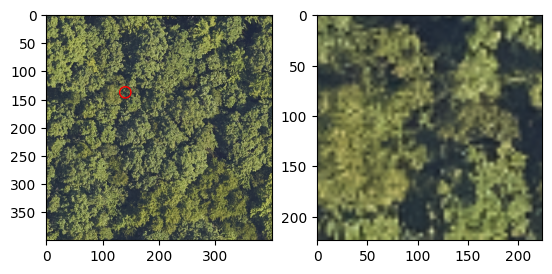

0


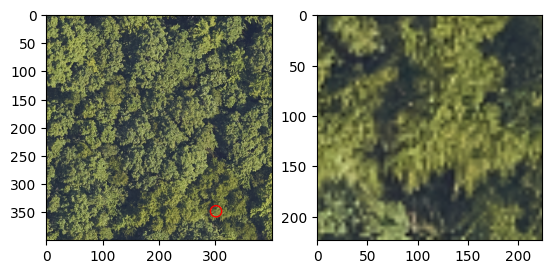

31_skogbrand_snoskader_robin_Hajern Ovre-bonn.png
0.029197247601278183


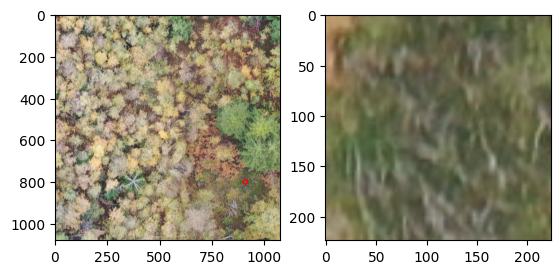

0.06065137919574613


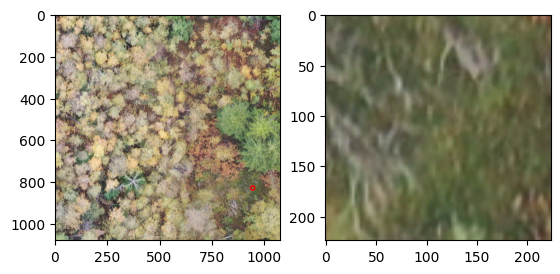

33_skogbrand_snoskader_robin_7879.png
0.08519414290267517


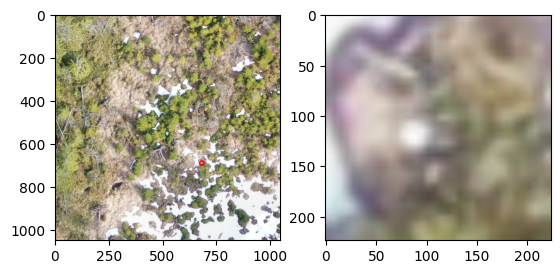

0.06300374616869109


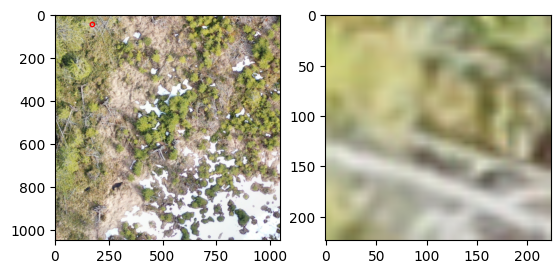

94_skogbrand_snoskader_robin_SB Store Gravdalstjern E.png
0


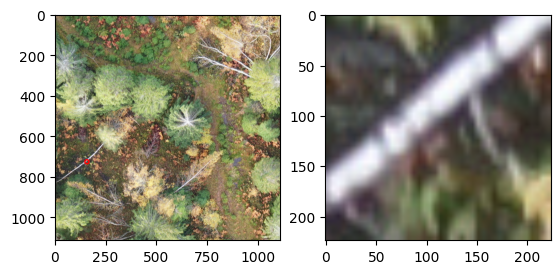

0.010974367438380707


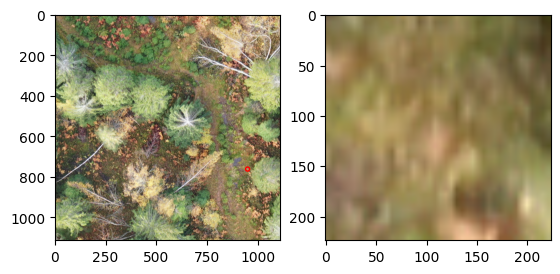

Flora Pluas RGB_12_7600_7600_11600_11600.png
too many attempts for Flora Pluas RGB_12_7600_7600_11600_11600.png
B05_0114.JPG
0.06667875446693945


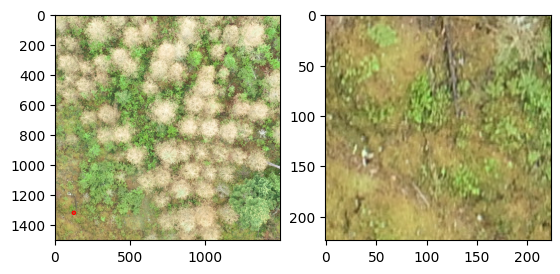

0.0684714256459928


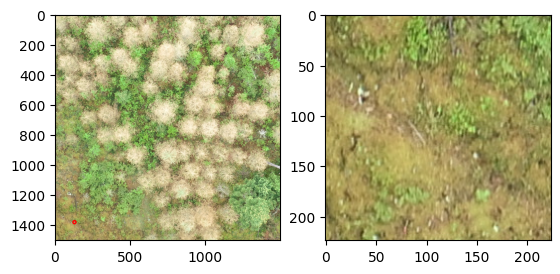

B09_0098.JPG
too many attempts for B09_0098.JPG
Carlos Vera Guevara RGB_5_3800_3800_7800_7800.png
0.08004929633597949


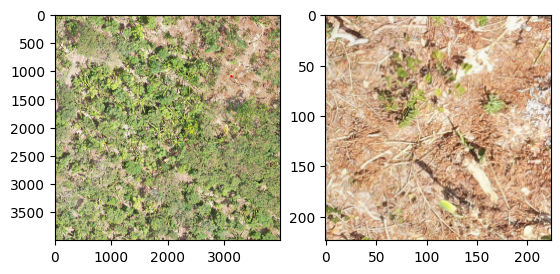

0.08090508888382043


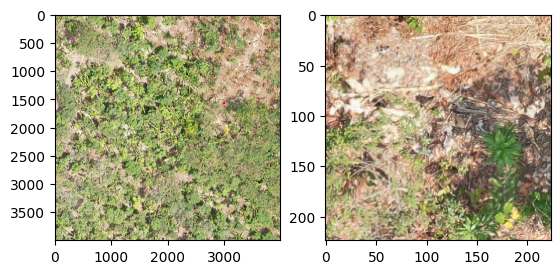

B06_0143.JPG
0.06797487714524865


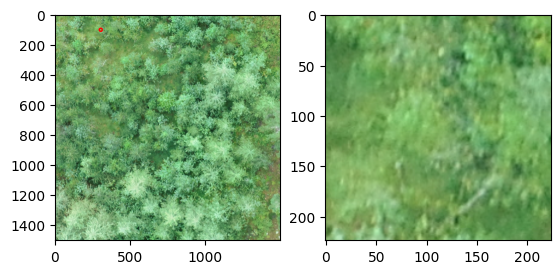

0.08601447418417024


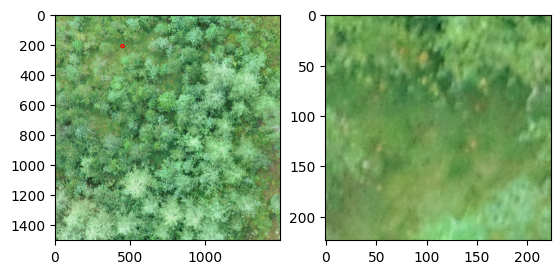

Pfinztal_6.png
0


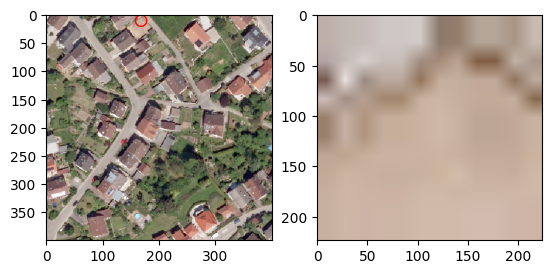

0


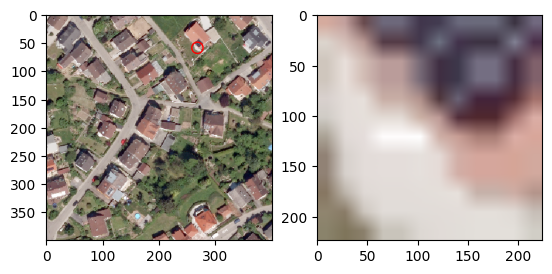

In [10]:
### testing neg

for i,fname in enumerate(df['filename'].unique()):
    print(fname)
    img_path = Path(IMAGES_DIR) / fname

    img = cv2.imread(str(img_path))
    img = cv2.cvtColor(img,cv2.COLOR_BGR2RGB)
    h,w,_ = img.shape

    img_boxes = df[df['filename'] == fname][['xmin','ymin','xmax','ymax']].astype(int).values

    
    used_cells = set()
    attempts = 0
    max_attempts = 10000

    side = pos_median_sides[i]
    stride = side/10

    IOU_NEG_THRESH = 0.09

    n_neg_target = 2
    neg_count = 0
    while neg_count < n_neg_target and attempts < max_attempts:
        cx = np.random.randint(int(side/2), w - int(side/2)) #from left to right
        cy = np.random.randint(int(side/2), h - int(side/2)) #from bottom to top
        
        # deduplicate
        gx,gy = cx // stride, cy // stride
        if (gx,gy) in used_cells:
            print("alr used")
            attempts += 1
            continue
        
        max_iou = max_iou_trees(cx,cy,side,img_boxes)
        
        if max_iou < IOU_NEG_THRESH:  
            print(max_iou)          
            patch = extract_negative_patch(img,cx,cy,side)
            
            fig,axes = plt.subplots(1,2)
            axes[0].imshow(img)
            rect = plt.Circle((cx,cy),radius=10,facecolor="none",edgecolor="red")
            axes[0].add_patch(rect)
            axes[1].imshow(patch)
            plt.show()
            
            used_cells.add((gx,gy))
            neg_count += 1
        attempts += 1
        
    if attempts >= max_attempts:
        print(f"too many attempts for {fname}")



